In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/clean_ceiling.csv")

In [3]:
df.head()

,timestamp,co2,temp
0,2025-10-15 07:33:03.311000+00:00,1418.00,22.14
1,2025-10-15 07:34:34.635000+00:00,1057.73,22.47
2,2025-10-15 07:35:00.959000+00:00,769.18,22.96
3,2025-10-15 07:35:57.285000+00:00,711.18,23.24
4,2025-10-15 07:36:56.302000+00:00,554.17,23.53


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 197622 entries, 0 to 197621
Data columns (total 3 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   timestamp  197622 non-null  str    
 1   co2        197622 non-null  float64
 2   temp       197622 non-null  float64
dtypes: float64(2), str(1)
memory usage: 4.5 MB


In [5]:
df.describe()

,co2,temp
count,197622.000000,197622.000000
mean,620.574905,25.687695
std,338.493936,0.579028
min,367.500000,22.140000
25%,441.250000,25.310000
50%,483.580000,25.640000
75%,664.180000,26.080000
max,4854.500000,27.860000


In [6]:
df.shape

(197622, 3)

In [7]:
df.isnull().sum()

timestamp    0
co2          0
temp         0
dtype: int64

In [8]:
df[df.duplicated()]

,timestamp,co2,temp


In [9]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    format="mixed",
    utc=True
)
df = df.sort_values(by="timestamp").reset_index(drop=True)

df.head()

,timestamp,co2,temp
0,2025-10-15 07:33:03.311000+00:00,1418.00,22.14
1,2025-10-15 07:34:34.635000+00:00,1057.73,22.47
2,2025-10-15 07:35:00.959000+00:00,769.18,22.96
3,2025-10-15 07:35:57.285000+00:00,711.18,23.24
4,2025-10-15 07:36:56.302000+00:00,554.17,23.53


In [10]:
print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

print("Is sorted:", df["timestamp"].is_monotonic_increasing)

First timestamp: 2025-10-15 07:33:03.311000+00:00
Last timestamp: 2026-03-03 22:59:36.761000+00:00
Is sorted: True


In [11]:
df[["co2", "temp"]] = df[["co2", "temp"]].interpolate(
    method="linear"
)

In [12]:
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (158097, 3)
Test: (39525, 3)


In [14]:
from sklearn.preprocessing import MinMaxScaler

features = ["co2", "temp"]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

In [15]:
def create_sequences(data, look_back=24):

    X, y = [], []

    for i in range(look_back, len(data)):

        X.append(data[i-look_back:i])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

In [16]:
X_train, y_train = create_sequences(train_scaled)

In [17]:
test_input = np.concatenate(
    [train_scaled[-24:], test_scaled],
    axis=0
)

X_test, y_test = create_sequences(test_input)

In [18]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (158073, 24, 2)
y_train: (158073,)
X_test: (39525, 24, 2)
y_test: (39525,)


In [19]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout
)

In [20]:
model = Sequential([
    Input(shape=(24, 2)),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 24, 64)              │          17,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 30,113 (117.63 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [22]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        "best_lstm_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        patience=5,
        factor=0.5,
        min_lr=0.00001,
        verbose=1
    )
]

In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=callbacks,
    shuffle=False,
    verbose=1
)

Epoch 1/100
3951/3952 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.0011 - mae: 0.0163
Epoch 1: val_loss improved from None to 0.00957, saving model to best_lstm_model.keras

Epoch 1: finished saving model to best_lstm_model.keras
3952/3952 ━━━━━━━━━━━━━━━━━━━━ 235s 56ms/step - loss: 0.0011 - mae: 0.0163 - val_loss: 0.0096 - val_mae: 0.0679 - learning_rate: 0.0010
Epoch 2/100
3952/3952 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 6.3881e-04 - mae: 0.0129
Epoch 2: val_loss improved from 0.00957 to 0.00802, saving model to best_lstm_model.keras

Epoch 2: finished saving model to best_lstm_model.keras
3952/3952 ━━━━━━━━━━━━━━━━━━━━ 218s 55ms/step - loss: 6.3881e-04 - mae: 0.0129 - val_loss: 0.0080 - val_mae: 0.0587 - learning_rate: 0.0010
Epoch 3/100
3951/3952 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 6.3523e-04 - mae: 0.0132
Epoch 3: val_loss improved from 0.00802 to 0.00127, saving model to best_lstm_model.keras

Epoch 3: finished saving model to best_lstm_model.keras
3952/3952 ━━━━━━━━━━━━━

In [24]:
y_pred = model.predict(X_test)

1236/1236 ━━━━━━━━━━━━━━━━━━━━ 43s 33ms/step


In [25]:
y_test_original = scaler.inverse_transform(
    np.column_stack([y_test, np.zeros(len(y_test))])
)[:, 0]

y_pred_original = scaler.inverse_transform(
    np.column_stack([y_pred.flatten(), np.zeros(len(y_pred))])
)[:, 0]

In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test_original, y_pred_original)

mse = mean_squared_error(y_test_original, y_pred_original)

rmse = np.sqrt(mse)

r2 = r2_score(y_test_original, y_pred_original)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")

MAE:  15.0965
MSE:  562.7934
RMSE: 23.7233
R2:   0.9931


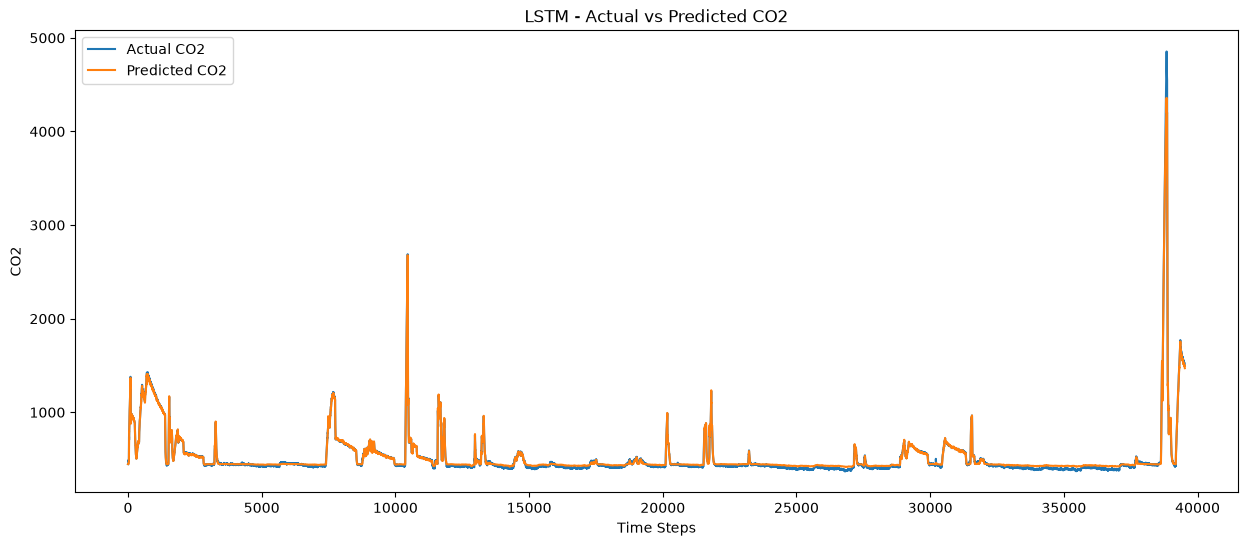

In [27]:
plt.figure(figsize=(15, 6))

plt.plot(y_test_original, label="Actual CO2")
plt.plot(y_pred_original, label="Predicted CO2")

plt.title("LSTM - Actual vs Predicted CO2")
plt.xlabel("Time Steps")
plt.ylabel("CO2")
plt.legend()
plt.show()

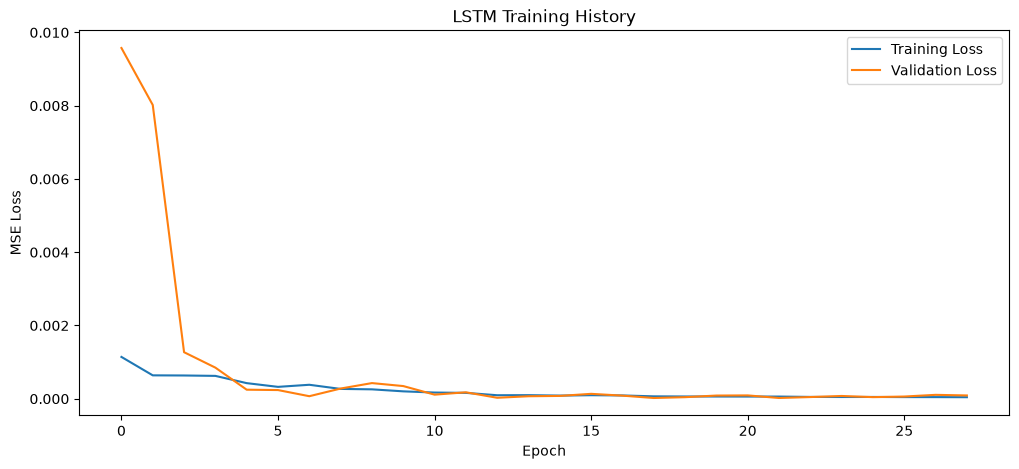

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [29]:
model.save("../model/co2_lstm.keras")